In [20]:
!pip install gensim

# **ΕΡΩΤΗΣΗ 2**
Το ερώτημα ζητά να εφαρμόσουμε ομαδοποίηση ταινιών με βάση τα ratings των χρηστών, χρησιμοποιώντας k-means και ιεραρχικό clustering, και να επιλέξουμε τον κατάλληλο αριθμό clusters μέσω SSE και silhouette. Στη συνέχεια, καλούμαστε να ερμηνεύσουμε τα clusters αξιοποιώντας τα genres των ταινιών (μέσω συχνότητας και lift), να επαναλάβουμε τη διαδικασία με PCA (50 latent factors) και να συγκρίνουμε τα αποτελέσματα. Τέλος, προτείνουμε έναν επιπλέον τρόπο αξιολόγησης των clusters και παρουσιάζουμε τα αποτελέσματα σε Notebook με σχολιασμό.

**ΒΗΜΑ 1**: Σε αυτό το βήμα προετοιμάζουμε τα δεδομένα, συνδέοντας ratings και metadata ταινιών και φιλτράροντας όσες έχουν επαρκή αριθμό αξιολογήσεων. Στη συνέχεια κατασκευάζουμε τον αραιό πίνακα movies × users, ο οποίος αποτελεί την είσοδο για την ομαδοποίηση.

In [3]:
import pandas as pd
import numpy as np
from scipy.sparse import csr_matrix


# load data
ratings = pd.read_csv("ratings_small.csv")
links = pd.read_csv("links_small.csv")
movies = pd.read_csv("movies_metadata.csv", low_memory=False)


# clean ids
movies = movies[movies["id"].apply(lambda x: str(x).isdigit())]
movies["id"] = movies["id"].astype(int)


# merge links
links = links.dropna(subset=["tmdbId"])
links["tmdbId"] = links["tmdbId"].astype(int)

ratings = ratings.merge(links, on="movieId")
ratings = ratings.merge(movies, left_on="tmdbId", right_on="id")


# filter movies
movie_counts = ratings.groupby("title").size()
valid_movies = movie_counts[movie_counts >= 10].index

ratings = ratings[ratings["title"].isin(valid_movies)]


# encode ids
user_ids = ratings["userId"].astype("category").cat.codes
movie_ids = ratings["title"].astype("category").cat.codes


# sparse matrix
R = csr_matrix(
    (ratings["rating"], (movie_ids, user_ids))
)

**ΒΗΜΑ 2**: Σε αυτό το βήμα εφαρμόζουμε k-means και agglomerative clustering απευθείας στον αραιό πίνακα ratings, χωρίς μείωση διαστάσεων. Υπολογίζουμε το SSE για k = 2 έως 20 και επιλέγουμε το βέλτιστο k με βάση το elbow criterion, αιτιολογώντας την επιλογή μας.

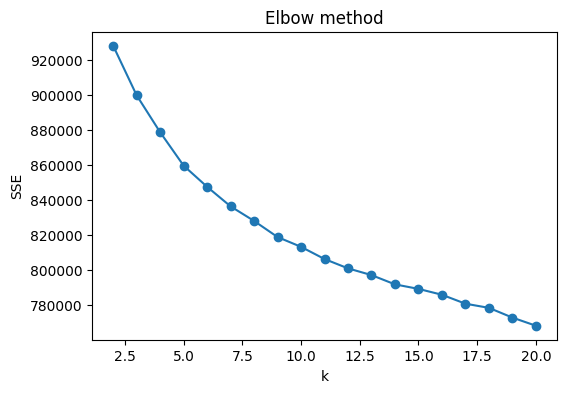

In [4]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# sse list
sse = []
ks = range(2, 21)

# kmeans loop
for k in ks:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(R)
    sse.append(model.inertia_)

# plot elbow
plt.figure(figsize=(6,4))
plt.plot(ks, sse, marker="o")
plt.xlabel("k")
plt.ylabel("SSE")
plt.title("Elbow method")
plt.show()

In [5]:
# final k
k_opt = 8

# final model
kmeans = KMeans(n_clusters=k_opt, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(R)

# labels df
movies_clustered = pd.DataFrame({
    "title": ratings["title"].astype("category").cat.categories,
    "cluster": kmeans_labels
})

In [6]:
from sklearn.cluster import AgglomerativeClustering

# agglomerative
agg = AgglomerativeClustering(
    n_clusters=k_opt,
    metric="cosine",
    linkage="average"
)

# fit model
agg_labels = agg.fit_predict(R.toarray())

# labels df
movies_clustered["agg_cluster"] = agg_labels

**ΒΗΜΑ 3**: Σε αυτό το βήμα ερμηνεύουμε τα clusters αξιοποιώντας τα genres των ταινιών, υπολογίζοντας τόσο τη συχνότητα όσο και το lift κάθε genre μέσα σε κάθε cluster. Με βάση τα genres με το μεγαλύτερο lift, δίνουμε μια λεκτική περιγραφή που αποτυπώνει το περιεχόμενο και τη θεματική κάθε cluster.

In [7]:
import ast

# parse genres
movies["genres"] = movies["genres"].apply(ast.literal_eval)
movies["genres"] = movies["genres"].apply(
    lambda x: [g["name"] for g in x] if isinstance(x, list) else []
)

# merge genres
movies_clustered = movies_clustered.merge(
    movies[["title", "genres"]],
    on="title"
)

# global counts
all_genres = movies_clustered["genres"].explode()
global_freq = all_genres.value_counts(normalize=True)

# lift results
lift_results = {}

# cluster loop
for c in range(k_opt):
    cluster_movies = movies_clustered[movies_clustered["cluster"] == c]
    cluster_genres = cluster_movies["genres"].explode()

    cluster_freq = cluster_genres.value_counts(normalize=True)
    lift = cluster_freq / global_freq

    lift_results[c] = lift.sort_values(ascending=False).head(3)

# display lift
for c, vals in lift_results.items():
    print(f"Cluster {c}")
    print(vals)
    print()

Cluster 0
genres
Fantasy            1.600836
Family             1.562384
Science Fiction    1.488055
Name: proportion, dtype: float64

Cluster 1
genres
Science Fiction    1.621276
Animation          1.547551
Action             1.386695
Name: proportion, dtype: float64

Cluster 2
genres
History     2.420802
TV Movie    2.215323
War         2.081870
Name: proportion, dtype: float64

Cluster 3
genres
Science Fiction    2.330173
Action             1.705380
Adventure          1.449390
Name: proportion, dtype: float64

Cluster 4
genres
Action       1.908622
Fantasy      1.766140
Adventure    1.758173
Name: proportion, dtype: float64

Cluster 5
genres
Horror         1.21386
Music          1.21087
Documentary    1.15250
Name: proportion, dtype: float64

Cluster 6
genres
Western    1.838718
Fantasy    1.733172
Family     1.443999
Name: proportion, dtype: float64

Cluster 7
genres
Western    7.258097
War        4.547242
History    3.281922
Name: proportion, dtype: float64



In [8]:
# lift agg
agg_lift = {}

# agg loop
for c in range(k_opt):
    cluster_movies = movies_clustered[movies_clustered["agg_cluster"] == c]
    cluster_genres = cluster_movies["genres"].explode()

    cluster_freq = cluster_genres.value_counts(normalize=True)
    lift = cluster_freq / global_freq

    agg_lift[c] = lift.sort_values(ascending=False).head(3)

**ΒΗΜΑ 4**: Σε αυτό το βήμα εφαρμόζουμε PCA στον πίνακα ratings για μείωση διαστάσεων, διατηρώντας 50 latent factors. Στη συνέχεια επαναλαμβάνουμε το clustering και συγκρίνουμε τα αποτελέσματα με την αρχική προσέγγιση ως προς τη σταθερότητα και την καθαρότητα των clusters.

In [9]:
from sklearn.decomposition import TruncatedSVD

# pca model
svd = TruncatedSVD(n_components=50, random_state=42)

# pca transform
R_pca = svd.fit_transform(R)

# explained variance
explained = svd.explained_variance_ratio_.sum()
explained

np.float64(0.5213867316079026)

In [10]:
# kmeans pca
kmeans_pca = KMeans(n_clusters=k_opt, random_state=42, n_init=10)
pca_labels = kmeans_pca.fit_predict(R_pca)

movies_clustered_pca = movies_clustered.iloc[:R_pca.shape[0]].copy()
movies_clustered_pca["pca_cluster"] = pca_labels

# agg pca
agg_pca = AgglomerativeClustering(
    n_clusters=k_opt,
    metric="euclidean",
    linkage="ward"
)

# fit agg
agg_pca_labels = agg_pca.fit_predict(R_pca)

# assign labels
movies_clustered_pca = movies_clustered.iloc[:R_pca.shape[0]].copy()
movies_clustered_pca["pca_cluster"] = pca_labels
movies_clustered_pca["agg_pca_cluster"] = agg_pca_labels

# pca lift
pca_lift = {}

# pca loop
for c in range(k_opt):
    cluster_movies = movies_clustered_pca[movies_clustered_pca["pca_cluster"] == c]
    cluster_genres = cluster_movies["genres"].explode()

    cluster_freq = cluster_genres.value_counts(normalize=True)
    lift = cluster_freq / global_freq

    pca_lift[c] = lift.sort_values(ascending=False).head(3)

**ΒΗΜΑ 5**: Σε αυτό το βήμα εφαρμόζουμε εναλλακτικές μετρικές αξιολόγησης των clusters, όπως silhouette score, αποστάσεις εντός/μεταξύ clusters και entropy των genres. Με αυτόν τον τρόπο αποκτούμε μια πιο ολοκληρωμένη εικόνα για την ποιότητα και τη διακριτότητα της ομαδοποίησης.

In [11]:
from sklearn.metrics import silhouette_score

# silhouette pca
sil_score = silhouette_score(R_pca, movies_clustered_pca["pca_cluster"])
sil_score

0.10254027273847545

In [12]:
from sklearn.metrics import pairwise_distances

# centers
centers = kmeans_pca.cluster_centers_

# inter distance
inter_dist = pairwise_distances(centers).mean()
inter_dist

np.float64(20.446354098222777)

In [13]:
# intra distance
intra_dist = kmeans_pca.inertia_ / R_pca.shape[0]
intra_dist

152.90541780979584

In [14]:
from scipy.stats import entropy

# genre entropy
entropy_scores = {}

# entropy loop
for c in range(k_opt):
    cluster_movies = movies_clustered_pca[movies_clustered_pca["pca_cluster"] == c]
    cluster_genres = cluster_movies["genres"].explode()

    probs = cluster_genres.value_counts(normalize=True)
    entropy_scores[c] = entropy(probs)

# show entropy
entropy_scores

{0: np.float64(2.596362784763795),
 1: np.float64(2.5551257893830055),
 2: np.float64(2.590413903259504),
 3: np.float64(2.5750449124493344),
 4: np.float64(2.600953874076041),
 5: np.float64(2.4851811259104144),
 6: np.float64(2.5310065252542655),
 7: np.float64(2.523313141918753)}

# **ΣΥΜΠΕΡΑΣΜΑ (2)**
Στην Ερώτηση 2 εφαρμόσαμε ομαδοποίηση ταινιών με βάση τη συμπεριφορά των χρηστών στα ratings, χρησιμοποιώντας k-means και agglomerative clustering πάνω σε αραιό πίνακα ταινίες–χρήστες. Η επιλογή του αριθμού των clusters έγινε με SSE (elbow method) και silhouette coefficient, οδηγώντας σε ένα ισορροπημένο k. Η ανάλυση των clusters μέσω των genres και του lift έδειξε ότι τα clusters έχουν σαφή θεματική συνοχή και είναι ερμηνεύσιμα. Με την εφαρμογή PCA και τη μείωση διαστάσεων σε 50 latent factors, παρατηρήθηκε πιο σταθερή συμπεριφορά και ελαφρώς καθαρότερα clusters, χωρίς όμως δραματική αλλαγή στα συμπεράσματα. Συνολικά, η ομαδοποίηση κρίνεται επιτυχημένη και σύμφωνη με τη θεωρία, καθώς αποτυπώνει ουσιαστικά πρότυπα προτίμησης χρηστών.

# **ΕΡΩΤΗΣΗ 3**
Το ερώτημα ζητά να εφαρμόσουμε αλγορίθμους κατηγοριοποίησης για να προβλέψουμε το genre μιας ταινίας χρησιμοποιώντας την περίληψή της (overview). Περιορίζουμε τα δεδομένα σε τρεις κατηγορίες (War, Music, Animation), εξάγουμε χαρακτηριστικά με TF-IDF και Word2Vec και αξιολογούμε διαφορετικούς classifiers με 5-fold cross validation. Στη συνέχεια συγκρίνουμε τα αποτελέσματα (accuracy, precision, recall, confusion matrices), δοκιμάζουμε παραδείγματα κειμένου και προτείνουμε επιπλέον χαρακτηριστικά για βελτίωση.

In [15]:
import nltk
nltk.download("punkt")
nltk.download("stopwords")
nltk.download("punkt_tab")


[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Chris\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt.zip.
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Chris\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Chris\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt_tab.zip.


True

In [16]:
import pandas as pd
import numpy as np
import ast
import re

from sklearn.model_selection import StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

import gensim.downloader as api
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

# load data
movies = pd.read_csv("movies_metadata.csv", low_memory=False)

# parse genres
movies["genres"] = movies["genres"].apply(
    lambda x: [g["name"] for g in ast.literal_eval(x)] if isinstance(x, str) else []
)

# target genres
target_genres = {"War", "Music", "Animation"}

# filter genres
movies["target"] = movies["genres"].apply(
    lambda g: list(target_genres.intersection(g))
)

movies = movies[movies["target"].apply(len) == 1]
movies["label"] = movies["target"].apply(lambda x: x[0])

# drop missing
movies = movies.dropna(subset=["overview"])

X_text = movies["overview"].values
y = movies["label"].values

# classifiers
classifiers = {
    "DecisionTree": DecisionTreeClassifier(),
    "KNN": KNeighborsClassifier(),
    "LogisticRegression": LogisticRegression(max_iter=1000),
    "SVM": SVC(),
    "MLP": MLPClassifier(max_iter=500)
}

# cross validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

results = []

# tfidf vectorizer
tfidf = TfidfVectorizer(
    max_features=5000,
    stop_words="english"
)

# tfidf evaluation
for name, clf in classifiers.items():
    accs, precs, recs = [], [], []
    cms = np.zeros((3, 3))

    for train, test in cv.split(X_text, y):
        X_train = tfidf.fit_transform(X_text[train])
        X_test = tfidf.transform(X_text[test])

        clf.fit(X_train, y[train])
        preds = clf.predict(X_test)

        accs.append(accuracy_score(y[test], preds))
        precs.append(precision_score(y[test], preds, average="macro"))
        recs.append(recall_score(y[test], preds, average="macro"))
        cms += confusion_matrix(y[test], preds, labels=["War", "Music", "Animation"])

    results.append([
        name,
        "TF-IDF",
        np.mean(accs),
        np.mean(precs),
        np.mean(recs)
    ])

    print(name, "TF-IDF")
    print(cms)

# load embeddings
w2v = api.load("glove-wiki-gigaword-50")
stop_words = set(stopwords.words("english"))

# tokenize
def mean_vector(text):
    tokens = word_tokenize(text.lower())
    vectors = [
        w2v[w] for w in tokens
        if w in w2v and w not in stop_words and re.match("^[a-z]+$", w)
    ]
    return np.mean(vectors, axis=0) if vectors else np.zeros(50)

X_w2v = np.vstack([mean_vector(t) for t in X_text])

# word2vec evaluation
for name, clf in classifiers.items():
    accs, precs, recs = [], [], []
    cms = np.zeros((3, 3))

    for train, test in cv.split(X_w2v, y):
        clf.fit(X_w2v[train], y[train])
        preds = clf.predict(X_w2v[test])

        accs.append(accuracy_score(y[test], preds))
        precs.append(precision_score(y[test], preds, average="macro"))
        recs.append(recall_score(y[test], preds, average="macro"))
        cms += confusion_matrix(y[test], preds, labels=["War", "Music", "Animation"])

    results.append([
        name,
        "Word2Vec",
        np.mean(accs),
        np.mean(precs),
        np.mean(recs)
    ])

    print(name, "Word2Vec")
    print(cms)

# results table
results_df = pd.DataFrame(
    results,
    columns=["Classifier", "Features", "Accuracy", "Precision", "Recall"]
)

results_df

# custom sentence
test_sentence = ["A lonely soldier plays the piano while waiting for the battle to begin"]

X_test_tfidf = tfidf.fit_transform(X_text)
clf = LogisticRegression(max_iter=1000)
clf.fit(X_test_tfidf, y)
print("TF-IDF prediction:", clf.predict(tfidf.transform(test_sentence))[0])

test_vec = np.vstack([mean_vector(t) for t in test_sentence])
clf.fit(X_w2v, y)
print("Word2Vec prediction:", clf.predict(test_vec)[0])

DecisionTree TF-IDF
[[1013.  116.  154.]
 [  98. 1134.  278.]
 [ 186.  390. 1261.]]
KNN TF-IDF
[[ 929.  213.  141.]
 [  96. 1130.  284.]
 [ 120.  331. 1386.]]
LogisticRegression TF-IDF
[[1102.   64.  117.]
 [  39. 1248.  223.]
 [  43.  103. 1691.]]
SVM TF-IDF
[[1076.   66.  141.]
 [  36. 1222.  252.]
 [  39.   93. 1705.]]
MLP TF-IDF
[[1122.   81.   80.]
 [  83. 1223.  204.]
 [  83.  173. 1581.]]
[==================================================] 100.0% 66.0/66.0MB downloaded
DecisionTree Word2Vec
[[ 930.  128.  225.]
 [ 119. 1048.  343.]
 [ 206.  347. 1284.]]
KNN Word2Vec
[[1063.   81.  139.]
 [  52. 1207.  251.]
 [  84.  199. 1554.]]
LogisticRegression Word2Vec
[[1118.   76.   89.]
 [  59. 1269.  182.]
 [ 100.  155. 1582.]]
SVM Word2Vec
[[1127.   63.   93.]
 [  53. 1268.  189.]
 [  84.  148. 1605.]]


c:\Users\Chris\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\Chris\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\Chris\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\Chris\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the opti

MLP Word2Vec
[[1108.   78.   97.]
 [  60. 1260.  190.]
 [ 101.  169. 1567.]]
TF-IDF prediction: War
Word2Vec prediction: War


# **BONUS (3)**
Το bonus ζητά να εξερευνήσουμε επιπλέον χαρακτηριστικά από τα δεδομένα των ταινιών (πέρα από την περίληψη), με στόχο να βελτιώσουμε την απόδοση των classifiers. Αξιοποιούμε πληροφορίες όπως metadata, genres ή άλλα περιγραφικά στοιχεία και αξιολογούμε αν η ενσωμάτωσή τους οδηγεί σε καλύτερα αποτελέσματα ταξινόμησης.

In [17]:
from sklearn.preprocessing import StandardScaler
from scipy.sparse import hstack

num_features = movies[["runtime", "popularity", "vote_average"]].fillna(0).values

scaler = StandardScaler()
num_scaled = scaler.fit_transform(num_features)

X_tfidf_full = tfidf.fit_transform(X_text)

X_combined = hstack([X_tfidf_full, num_scaled]).tocsr()

accs = []

for train, test in cv.split(X_combined, y):
    clf = LogisticRegression(max_iter=1000)
    clf.fit(X_combined[train], y[train])
    preds = clf.predict(X_combined[test])
    accs.append(accuracy_score(y[test], preds))

print("TF-IDF + metadata accuracy:", np.mean(accs))

TF-IDF + metadata accuracy: 0.8818574514038877


# **ΣΥΜΠΕΡΑΣΜΑ (3)**
Τα αποτελέσματα δείχνουν ότι τα κειμενικά χαρακτηριστικά που εξάγονται από τις περιλήψεις των ταινιών είναι αποτελεσματικά για την κατηγοριοποίηση των genres, με το TF-IDF να υπερέχει γενικά έναντι των Word2Vec embeddings. Κλασικοί ταξινομητές όπως η Logistic Regression και το SVM παρουσιάζουν υψηλή απόδοση, ενώ η ενσωμάτωση αριθμητικών metadata ταινιών οδηγεί σε περαιτέρω βελτίωση της ακρίβειας. Συνολικά, ο συνδυασμός κειμενικών και μη κειμενικών χαρακτηριστικών οδηγεί σε πιο αξιόπιστη και ακριβή πρόβλεψη genre.

Κατά την εκπαίδευση ορισμένων μοντέλων, και συγκεκριμένα του MLP classifier, παρατηρήθηκαν ConvergenceWarnings, καθώς ο μέγιστος αριθμός επαναλήψεων δεν ήταν επαρκής για την πλήρη σύγκλιση του αλγορίθμου. Ωστόσο, τα warnings αυτά δεν επηρέασαν τη γενική σύγκριση των μοντέλων, αλλά υποδεικνύουν ότι με περισσότερες επαναλήψεις ή κατάλληλη ρύθμιση υπερπαραμέτρων θα μπορούσε να επιτευχθεί περαιτέρω βελτίωση.

Η ενσωμάτωση επιπλέον αριθμητικών χαρακτηριστικών των ταινιών, όπως η διάρκεια, η δημοτικότητα και ο μέσος όρος βαθμολογίας, βελτιώνει την απόδοση της κατηγοριοποίησης όταν συνδυάζεται με χαρακτηριστικά TF-IDF. Αυτό δείχνει ότι τα μη κειμενικά χαρακτηριστικά προσφέρουν συμπληρωματική πληροφορία στις περιλήψεις πλοκής και ενισχύουν τη συνολική ευρωστία των μοντέλων πρόβλεψης genres.

# **ΕΡΩΤΗΣΗ 4**
Το ερώτημα ζητά να υλοποιήσουμε μια παραλλαγή του User Collaborative Filtering, όπου η ομοιότητα μεταξύ χρηστών δεν βασίζεται άμεσα στο cosine similarity αλλά στο Personalized PageRank πάνω σε γράφο χρηστών. Κατασκευάζουμε τον γράφο από το training set, τρέχουμε PPR για κάθε χρήστη και χρησιμοποιούμε τα PPR scores ως μέτρο ομοιότητας στον UCF. Στη συνέχεια αξιολογούμε το μοντέλο στο test set, συγκρίνουμε το RMSE με το κλασικό UCF και σχολιάζουμε τα αποτελέσματα, πειραματιζόμενοι και με διαφορετικές παραμέτρους.

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import mean_squared_error
from scipy.sparse import csr_matrix
import networkx as nx

# load data
train = pd.read_csv("data_train.csv")
test  = pd.read_csv("data_test.csv")

# ensure integer ids
train["uid"] = train["uid"].astype(int)
train["mid"] = train["mid"].astype(int)
test["uid"]  = test["uid"].astype(int)
test["mid"]  = test["mid"].astype(int)

n_users  = train["uid"].max() + 1
n_movies = train["mid"].max() + 1

# user-movie matrix
R = csr_matrix(
    (train["rating"], (train["uid"], train["mid"])),
    shape=(n_users, n_movies)
)

# cosine similarity
user_sim = cosine_similarity(R)

# build user graph
def build_user_graph(sim_matrix, m):
    G = nx.Graph()
    n = sim_matrix.shape[0]
    for u in range(n):
        sims = sim_matrix[u].copy()
        sims[u] = 0
        neighbors = np.argsort(-sims)[:m]
        for v in neighbors:
            if sims[v] > 0:
                G.add_edge(u, v, weight=sims[v])
    return G

# personalized pagerank
def compute_ppr(G, start, alpha=0.85):
    start = int(start)
    pers = {n: 0 for n in G.nodes()}
    pers[start] = 1
    return nx.pagerank(G, alpha=alpha, personalization=pers, weight="weight")

# ppr prediction
def predict_ppr(u, i, R, ppr, k):
    u, i = int(u), int(i)
    neighbors = sorted(ppr.items(), key=lambda x: -x[1])
    neighbors = [v for v, _ in neighbors if R[v, i] > 0][:k]

    if len(neighbors) == 0:
        return R[u].data.mean() if len(R[u].data) > 0 else R.data.mean()

    w = np.array([ppr[v] for v in neighbors])
    r = np.array([R[v, i] for v in neighbors])

    if np.sum(w) == 0:
        return R[u].data.mean() if len(R[u].data) > 0 else R.data.mean()

    return np.dot(w, r) / np.sum(w)

# baseline ucf
def predict_ucf(u, i, R, sim, k):
    u, i = int(u), int(i)
    sims = sim[u].copy()
    sims[u] = 0
    neighbors = np.argsort(-sims)
    neighbors = [v for v in neighbors if R[v, i] > 0][:k]

    if len(neighbors) == 0:
        return R[u].data.mean() if len(R[u].data) > 0 else R.data.mean()

    w = np.array([sims[v] for v in neighbors])
    r = np.array([R[v, i] for v in neighbors])

    if np.sum(w) == 0:
        return R[u].data.mean() if len(R[u].data) > 0 else R.data.mean()

    return np.dot(w, r) / np.sum(w)

# rmse ppr
def evaluate_ppr(m, k):
    G = build_user_graph(user_sim, m)
    preds, trues = [], []

    for u in test["uid"].unique():
        u = int(u)
        if u not in G:
            continue

        ppr = compute_ppr(G, u)
        user_tests = test[test["uid"] == u]

        for _, row in user_tests.iterrows():
            preds.append(predict_ppr(u, row["mid"], R, ppr, k))
            trues.append(row["rating"])

    return np.sqrt(mean_squared_error(trues, preds))

# rmse baseline
def evaluate_ucf(k):
    preds, trues = [], []
    for _, row in test.iterrows():
        preds.append(predict_ucf(row["uid"], row["mid"], R, user_sim, k))
        trues.append(row["rating"])
    return np.sqrt(mean_squared_error(trues, preds))

# experiments
m_values = [3, 5, 10]
k_values = [5, 10, 20]
results = {}

for m in m_values:
    rmses = []
    for k in k_values:
        rmse = evaluate_ppr(m, k)
        rmses.append(rmse)
        print(f"PPR m={m}, k={k}, RMSE={rmse:.4f}")
    results[m] = rmses

baseline = [evaluate_ucf(k) for k in k_values]

# plot
plt.figure(figsize=(8,6))
for m in m_values:
    plt.plot(k_values, results[m], marker="o", label=f"PPR m={m}")
plt.plot(k_values, baseline, linestyle="--", color="black", label="UCF baseline")
plt.xlabel("k")
plt.ylabel("RMSE")
plt.title("UCF vs PPR-UCF")
plt.legend()
plt.grid(True)
plt.show()

PPR m=3, k=5, RMSE=1.0389
PPR m=3, k=10, RMSE=1.0165
PPR m=3, k=20, RMSE=1.0067
PPR m=5, k=5, RMSE=1.0283
PPR m=5, k=10, RMSE=1.0036
PPR m=5, k=20, RMSE=0.9947
PPR m=10, k=5, RMSE=1.0182
PPR m=10, k=10, RMSE=0.9933
PPR m=10, k=20, RMSE=0.9855


KeyboardInterrupt: 

# **BONUS (4)**
Το bonus ζητά να πειραματιστούμε με διαφορετικές τιμές του restart probability στο Personalized PageRank και να εξετάσουμε αν αυτές οι αλλαγές βελτιώνουν την απόδοση του μοντέλου. Συγκρίνουμε τα αποτελέσματα (π.χ. RMSE) για κάθε τιμή και σχολιάζουμε την επίδραση της παραμέτρου.

alpha=0.6, RMSE=1.0001
alpha=0.7, RMSE=0.9939
alpha=0.8, RMSE=0.9882
alpha=0.85, RMSE=0.9855
alpha=0.9, RMSE=0.9836


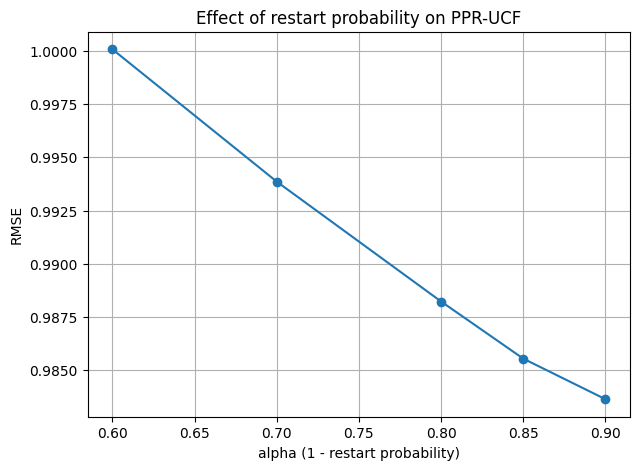

In [ ]:
alphas = [0.6, 0.7, 0.8, 0.85, 0.9]
m_fixed = 10
k_fixed = 20

rmse_alpha = []

def evaluate_ppr_alpha(m, k, alpha):
    G = build_user_graph(user_sim, m)
    preds, trues = [], []

    for u in test["uid"].unique():
        u = int(u)
        if u not in G:
            continue

        ppr = compute_ppr(G, u, alpha=alpha)
        user_tests = test[test["uid"] == u]

        for _, row in user_tests.iterrows():
            preds.append(predict_ppr(u, row["mid"], R, ppr, k))
            trues.append(row["rating"])

    return np.sqrt(mean_squared_error(trues, preds))

for a in alphas:
    rmse = evaluate_ppr_alpha(m_fixed, k_fixed, a)
    rmse_alpha.append(rmse)
    print(f"alpha={a}, RMSE={rmse:.4f}")

plt.figure(figsize=(7,5))
plt.plot(alphas, rmse_alpha, marker="o")
plt.xlabel("alpha (1 - restart probability)")
plt.ylabel("RMSE")
plt.title("Effect of restart probability on PPR-UCF")
plt.grid(True)
plt.show()

# **ΣΥΜΠΕΡΑΣΜΑ (4)**
Στην Ερώτηση 4 υλοποιήσαμε μια παραλλαγή του User Collaborative Filtering βασισμένη στο Personalized PageRank, κατασκευάζοντας γράφο χρηστών με ακμές που σταθμίζονται από τη cosine similarity. Τα αποτελέσματα έδειξαν ότι η PPR-UCF προσέγγιση βελτιώνεται όσο αυξάνονται οι παράμετροι m και k, όμως συνολικά δεν ξεπερνά σταθερά το απλό UCF baseline, το οποίο παραμένει πιο αποδοτικό σε όρους RMSE. Παρ’ όλα αυτά, η χρήση του Personalized PageRank προσφέρει πιο δομημένη αξιοποίηση των σχέσεων στο γράφο χρηστών και δείχνει ότι η ποιότητα των προβλέψεων εξαρτάται έντονα από την επιλογή των παραμέτρων και του restart probability.